Model Evaluation
**Week 3 | AI and Machine Learning Track**

### Learning objectives
By the end of this session, you will be able to:
1. Evaluate regression models with MAE, MSE, RMSE and R²
2. Read a confusion matrix and calculate accuracy, precision, recall and F1
3. Explain why accuracy can be misleading
4. Recognise overfitting and underfitting
5. Use cross-validation for a more reliable score

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.datasets import load_breast_cancer
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score,
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay, classification_report,
)

np.random.seed(7)

# Part A: Evaluating Regression Models
We rebuild the house-price model from Session 2.

In [2]:
houses = pd.read_csv("houses.csv")

X = houses.drop(columns="price_million")
y = houses["price_million"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

reg_model = LinearRegression().fit(X_train, y_train)
y_pred = reg_model.predict(X_test)

## 1. Regression metrics
| Metric | What it tells you | Good value |
|---|---|---|
| **MAE** (Mean Absolute Error) | Average size of the error, in the same unit as the target | Lower is better |
| **MSE** (Mean Squared Error) | Average of squared errors; punishes big mistakes heavily | Lower is better |
| **RMSE** (Root MSE) | Square root of MSE; back in the original unit | Lower is better |
| **R²** | Share of the variation in the target the model explains | Closer to 1 is better |

In [3]:
mae  = mean_absolute_error(y_test, y_pred)
mse  = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2   = r2_score(y_test, y_pred)

print(f"MAE : {mae:.2f}  -> on average, predictions are off by about N{mae:.1f} million")
print(f"MSE : {mse:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"R²  : {r2:.3f}  -> the model explains about {r2*100:.0f}% of the variation in prices")

MAE : 4.13  -> on average, predictions are off by about N4.1 million
MSE : 29.47
RMSE: 5.43
R²  : 0.977  -> the model explains about 98% of the variation in prices


**Discussion:** If the residuals formed a curve or a funnel shape instead of a random cloud, what would that tell us about the model?

# Part B: Evaluating Classification Models
We use the breast cancer dataset: predict whether a tumour is **malignant (0)** or **benign (1)**.

In [6]:
cancer = load_breast_cancer(as_frame=True)
Xc, yc = cancer.data, cancer.target

Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    Xc, yc, test_size=0.2, random_state=42, stratify=yc
)

clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
clf.fit(Xc_train, yc_train)
yc_pred = clf.predict(Xc_test)

## 2. The Confusion Matrix
A table showing where the model was right and where it was wrong.

|  | Predicted: Negative | Predicted: Positive |
|---|---|---|
| **Actual: Negative** | True Negative (TN) | False Positive (FP) |
| **Actual: Positive** | False Negative (FN) | True Positive (TP) |

**Note for this dataset:** scikit-learn labels *benign* as 1, so "positive" here means benign. The dangerous mistake is a **False Positive**: a malignant tumour wrongly predicted as benign.

[[41  1]
 [ 1 71]]


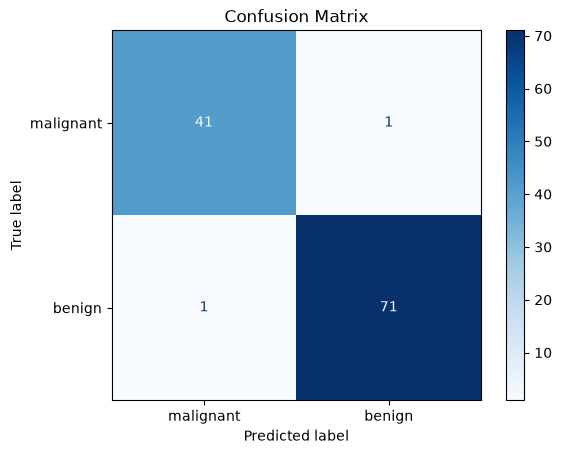

In [7]:
cm = confusion_matrix(yc_test, yc_pred)
print(cm)

ConfusionMatrixDisplay(cm, display_labels=cancer.target_names).plot(cmap="Blues")
plt.title("Confusion Matrix")
plt.show()

In [8]:
tn, fp, fn, tp = cm.ravel()
print(f"True Negatives : {tn}  (malignant, correctly predicted malignant)")
print(f"False Positives: {fp}  (malignant, wrongly predicted benign)")
print(f"False Negatives: {fn}  (benign, wrongly predicted malignant)")
print(f"True Positives : {tp}  (benign, correctly predicted benign)")

True Negatives : 41  (malignant, correctly predicted malignant)
False Positives: 1  (malignant, wrongly predicted benign)
False Negatives: 1  (benign, wrongly predicted malignant)
True Positives : 71  (benign, correctly predicted benign)


## 3. Classification metrics
| Metric | Question it answers | Formula |
|---|---|---|
| **Accuracy** | Of all predictions, how many were correct? | (TP + TN) / Total |
| **Precision** | When the model says "positive", how often is it right? | TP / (TP + FP) |
| **Recall** | Of all real positives, how many did the model find? | TP / (TP + FN) |
| **F1-score** | Balance between precision and recall | 2 × (P × R) / (P + R) |

In [9]:
print(f"Accuracy : {accuracy_score(yc_test, yc_pred):.3f}")
print(f"Precision: {precision_score(yc_test, yc_pred):.3f}")
print(f"Recall   : {recall_score(yc_test, yc_pred):.3f}")
print(f"F1-score : {f1_score(yc_test, yc_pred):.3f}")

Accuracy : 0.982
Precision: 0.986
Recall   : 0.986
F1-score : 0.986


In [10]:
# One call that gives everything per class
print(classification_report(yc_test, yc_pred, target_names=cancer.target_names))

              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



## 4. Why accuracy can be misleading
Imagine a disease that only **5 in 100** people have. A "lazy model" that always says **"healthy"** is 95% accurate, yet it finds **none** of the sick people!

In [11]:
# 95 healthy (0), 5 sick (1)
actual = np.array([0] * 95 + [1] * 5)
lazy_prediction = np.zeros(100, dtype=int)     # always predicts "healthy"

print("Accuracy:", accuracy_score(actual, lazy_prediction))
print("Recall  :", recall_score(actual, lazy_prediction), "<- it found 0% of the sick patients")

Accuracy: 0.95
Recall  : 0.0 <- it found 0% of the sick patients


### Which metric matters most?
- **Medical screening / fraud detection:** missing a real case is costly, so **Recall** matters most.
- **Spam filter:** wrongly blocking a real email is costly, so **Precision** matters most.
- **Balanced classes, no clear priority:** **Accuracy** or **F1** is fine.

# Part C: Overfitting and Underfitting
- **Underfitting:** the model is too simple and performs poorly on both training and test data.
- **Overfitting:** the model memorises the training data and performs well on training data but poorly on new data.
- **Good fit:** performs well on both.

We will show this by changing the depth (complexity) of a decision tree.

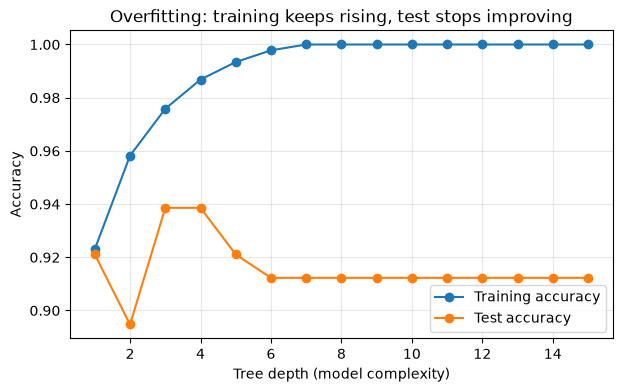

In [12]:
depths = range(1, 16)
train_scores, test_scores = [], []

for d in depths:
    tree = DecisionTreeClassifier(max_depth=d, random_state=42)
    tree.fit(Xc_train, yc_train)
    train_scores.append(tree.score(Xc_train, yc_train))
    test_scores.append(tree.score(Xc_test, yc_test))

plt.figure(figsize=(7, 4))
plt.plot(depths, train_scores, marker="o", label="Training accuracy")
plt.plot(depths, test_scores, marker="o", label="Test accuracy")
plt.xlabel("Tree depth (model complexity)")
plt.ylabel("Accuracy")
plt.title("Overfitting: training keeps rising, test stops improving")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**How to read the graph:**
- Very low depth: both scores are lower, so the model is **underfitting**.
- High depth: training accuracy reaches ~100% but test accuracy stays flat or drops, so the model is **overfitting**.
- The best depth is where the test score is highest.

In [13]:
best_depth = list(depths)[int(np.argmax(test_scores))]
print("Depth with the best test accuracy:", best_depth)

Depth with the best test accuracy: 3


# Part D: Cross-Validation
One train-test split can be lucky or unlucky. **Cross-validation** splits the data several times (here 5 folds), trains and tests each time, and averages the results for a more trustworthy score.

In [14]:
cv_scores = cross_val_score(clf, Xc, yc, cv=5)

print("Scores for each fold:", cv_scores.round(3))
print(f"Average accuracy: {cv_scores.mean():.3f}  (+/- {cv_scores.std():.3f})")

Scores for each fold: [0.982 0.982 0.974 0.974 0.991]
Average accuracy: 0.981  (+/- 0.007)


In [15]:
# Compare models fairly with cross-validation
models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "Decision Tree (depth 3)": DecisionTreeClassifier(max_depth=3, random_state=42),
    "Decision Tree (no limit)": DecisionTreeClassifier(random_state=42),
}

for name, mdl in models.items():
    scores = cross_val_score(mdl, Xc, yc, cv=5)
    print(f"{name:26s} mean accuracy = {scores.mean():.3f}")

Logistic Regression        mean accuracy = 0.981
Decision Tree (depth 3)    mean accuracy = 0.919
Decision Tree (no limit)   mean accuracy = 0.917


## Practice exercises
1. Re-run the regression metrics after removing `distance_km` from the features. Does R² go up or down?
2. For the breast cancer model, which is more dangerous: a **false positive** or a **false negative**? Which metric would you focus on?
3. Change the decision tree depth range to `range(1, 30)`. Where does overfitting become clear?
4. Run `cross_val_score` with `cv=10` instead of `cv=5`. Does the average change?

## Key takeaways
- **Regression:** MAE, RMSE and R² tell you how far off your predictions are.
- **Classification:** use the confusion matrix, precision, recall and F1, not accuracy alone.
- Choose the metric that matches the **cost of the mistake**.
- **Overfitting** = memorising; **underfitting** = too simple.
- **Cross-validation** gives a more reliable estimate than a single split.